# 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
import sklearn

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11})
print('scikit-learn version:', sklearn.__version__)
print('Positive class: 1 = pass; negative class: 0 = fail.')

scikit-learn version: 1.6.1
Positive class: 1 = pass; negative class: 0 = fail.


## 2. Create and inspect our classroom data
Each row describes one fictional student. `hours_studied` is the input $x$; `passed` is the label $y$.

In [ ]:
rng = np.random.default_rng(42)
hours = rng.uniform(0, 10, size=240)
# Hidden data-generating rule, used only to simulate classroom outcomes.
hidden_probability = 1 / (1 + np.exp(-(-4 + 0.8 * hours)))
passed = rng.binomial(1, hidden_probability)
data = pd.DataFrame({'hours_studied': hours, 'passed': passed})
display(data.head(8).round(2))
print('Number of examples:', len(data))
print('Observed pass fraction:', round(data['passed'].mean(), 3))

,hours_studied,passed
0,7.74,1
1,4.39,1
2,8.59,1
3,6.97,1
4,0.94,0
5,9.76,1
6,7.61,1
7,7.86,1


Number of examples: 240
Observed pass fraction: 0.446


### Train-test split
`stratify=y` approximately preserves the class proportions in each set.

In [ ]:
X = data[['hours_studied']]  # A two-dimensional feature table.
y = data['passed']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=7, stratify=y)
print(f'Training examples: {len(X_train)}; test examples: {len(X_test)}')

Training examples: 180; test examples: 60


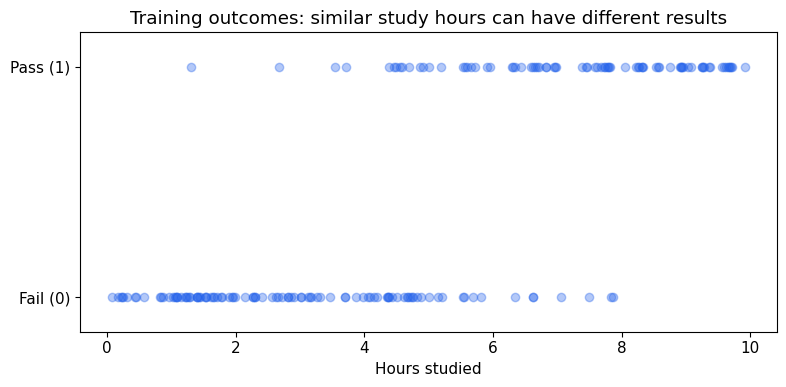

In [ ]:
plt.scatter(X_train['hours_studied'], y_train, alpha=0.35, color='#2563eb')

plt.yticks([0, 1], ['Fail (0)', 'Pass (1)'])
plt.xlabel('Hours studied')
plt.title('Training outcomes: similar study hours can have different results')

plt.ylim(-0.15, 1.15)
plt.tight_layout()
plt.show()

## 3. Why a straight line is not a probability
Linear regression fits $\hat y=b+wx$. Even with 0/1 training labels, its predictions are unbounded.

**Predict before running:** can the fitted line produce a value below 0 or above 1?

In [ ]:
linear_model = LinearRegression().fit(X_train, y_train)

# predict on 300 data points
grid = pd.DataFrame({'hours_studied': np.linspace(0, 10, 300)})
linear_predictions = linear_model.predict(grid)
print(linear_predictions[0].round(3))

-0.186


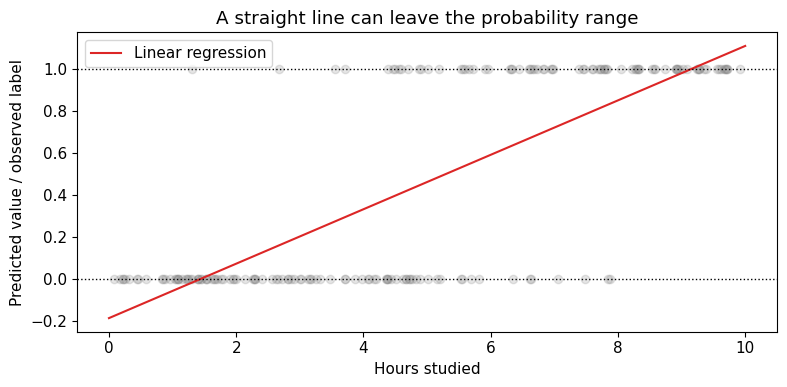

Predicted range on 0–10 hours: -0.186 to 1.111
Clipping this line would not fit a logistic regression model.


In [ ]:
plt.scatter(X_train['hours_studied'], y_train, alpha=0.2, color='gray')
plt.plot(grid['hours_studied'], linear_predictions, color='#dc2626', label='Linear regression')

plt.axhline(0, color='black', linestyle=':', linewidth=1)
plt.axhline(1, color='black', linestyle=':', linewidth=1)

plt.xlabel('Hours studied')
plt.ylabel('Predicted value / observed label')
plt.title('A straight line can leave the probability range')
plt.legend()
plt.tight_layout()
plt.show()

print('Predicted range on 0–10 hours:', linear_predictions.min().round(3), 'to', linear_predictions.max().round(3))
print('Clipping this line would not fit a logistic regression model.')

## 4. From a linear score to a probability
Keep the score $z=b+wx$. Model the **log-odds** as this score:

$$\log\left(\frac{p}{1-p}\right)=z.$$

Exponentiate and rearrange:

$$\frac{p}{1-p}=e^z \quad\Rightarrow\quad p=e^z(1-p)
\quad\Rightarrow\quad p=\frac{1}{1+e^{-z}}.$$

This is the **sigmoid**, $\sigma(z)$. It maps a real score to a probability between 0 and 1. We chose to make log-odds linear; this is a new modeling assumption, not an algebraic consequence of ordinary least squares.

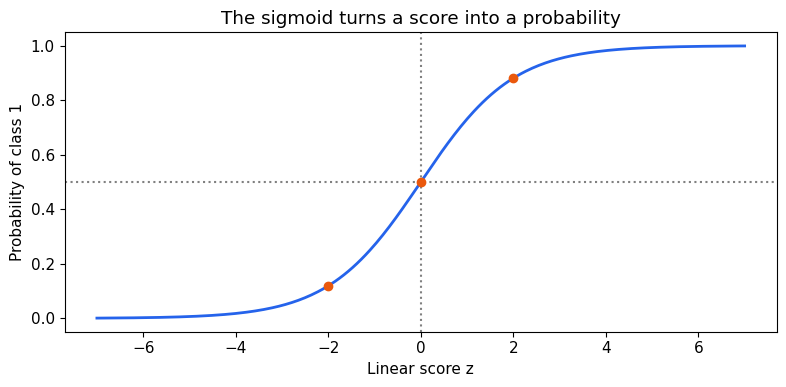

Scores -2, 0, 2 map to: [0.119 0.5   0.881]


In [ ]:
def sigmoid(z):
    # Clipping here only avoids numerical overflow for extreme demo inputs.
    return 1 / (1 + np.exp(-np.clip(np.asarray(z, dtype=float), -500, 500)))

scores = np.linspace(-7, 7, 300)

plt.plot(scores, sigmoid(scores), color='#2563eb', linewidth=2)
plt.scatter([-2, 0, 2], sigmoid([-2, 0, 2]), color='#ea580c', zorder=3)

plt.axhline(0.5, color='gray', linestyle=':')
plt.axvline(0, color='gray', linestyle=':')

plt.xlabel('Linear score z')
plt.ylabel('Probability of class 1')
plt.title('The sigmoid turns a score into a probability')
plt.tight_layout()
plt.show()
print('Scores -2, 0, 2 map to:', sigmoid([-2, 0, 2]).round(3))

### Try hand-chosen weights
Use $b=-4$ and $w=0.8$. These are illustrative values, not learned model coefficients.
For six hours: $z=-4+0.8(6)=0.8$ and $p\approx0.690$.

A 69% estimated chance of passing is not an exam score of 69%.

In [ ]:
example_hours = np.array([2, 5, 6, 8])
example_scores = -4 + 0.8 * example_hours
example_probabilities = sigmoid(example_scores)
display(pd.DataFrame({
    'hours': example_hours,
    'score': example_scores,
    'P(pass)': example_probabilities,
    'prediction_at_0.5': (example_probabilities >= 0.5).astype(int)
}).round(3))

,hours,score,P(pass),prediction_at_0.5
0,2,-2.4,0.083,0
1,5,0.0,0.500,1
2,6,0.8,0.690,1
3,8,2.4,0.917,1


## 5. How training knows what is better
For one example, **log loss** is:

$$\ell(y,p)=-[y\log p+(1-y)\log(1-p)].$$

When the actual label is 1, the loss becomes $-\log p$. Assigning high probability to the observed result gives lower loss. Confident mistakes get a large penalty.

Training finds weights that reduce average loss. Our library model also uses default regularization, which discourages overly large weights. The optimization mathematics is optional.

In [ ]:
trial_probabilities = np.array([0.9, 0.5, 0.1])
display(pd.DataFrame({
    'actual_label': [1, 1, 1],
    'predicted_P(pass)': trial_probabilities,
    'log_loss': -np.log(trial_probabilities)
}).round(3))

,actual_label,predicted_P(pass),log_loss
0,1,0.9,0.105
1,1,0.5,0.693
2,1,0.1,2.303


## 6. Train logistic regression and inspect its curve
`fit` learns the intercept and coefficient from the training examples. `predict_proba` returns one probability column for each entry in `classes_`; we explicitly find the column for label 1.

We keep hours in their original units for easy interpretation. With many features in different units, scaling in a preprocessing pipeline becomes useful.

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pass_column = list(model.classes_).index(1)
b = float(model.intercept_[0])
w = float(model.coef_[0, 0])
print(f'Learned score: z = {b:.3f} + ({w:.3f} × hours)')
print('Probability-column labels:', model.classes_)
print('A positive coefficient raises P(pass), not by a fixed number of percentage points.')

Learned score: z = -5.059 + (0.945 × hours)
Probability-column labels: [0 1]
A positive coefficient raises P(pass), not by a fixed number of percentage points.


In [ ]:
# curve_probability = model.predict_proba(grid)[:, pass_column]
# plt.scatter(X_train['hours_studied'], y_train, alpha=0.22, color='gray', label='Training outcomes')
# plt.plot(grid['hours_studied'], curve_probability, color='#2563eb', linewidth=2, label='Learned P(pass)')
# plt.axhline(0.5, color='#ea580c', linestyle='--', label='Threshold = 0.5')
# if abs(w) > 1e-12:
#     boundary = -b / w
#     if 0 <= boundary <= 10:
#         plt.axvline(boundary, color='gray', linestyle=':', label=f'Boundary ≈ {boundary:.2f} hours')
# plt.xlabel('Hours studied')
# plt.ylabel('Probability / observed label')
# plt.title('Logistic regression: an estimated probability, not a guarantee')
# plt.ylim(-0.08, 1.08)
# plt.legend(loc='upper left', fontsize=9)
# plt.tight_layout()
# plt.show()

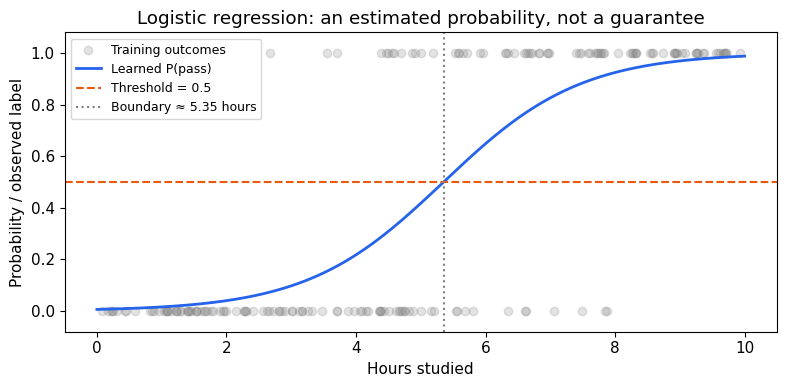

In [ ]:
threshold = 0.5  # Choose a value strictly between 0 and 1.

if not 0 < threshold < 1:
    raise ValueError("Threshold must be strictly between 0 and 1.")

curve_probability = model.predict_proba(grid)[:, pass_column]

plt.scatter(X_train['hours_studied'], y_train, alpha=0.22, color='gray', label='Training outcomes')
plt.plot(grid['hours_studied'], curve_probability, color='#2563eb', linewidth=2, label='Learned P(pass)')

plt.axhline(threshold, color='#ea580c', linestyle='--', label=f'Threshold = {threshold}')

if abs(w) > 1e-12:
    boundary = (np.log(threshold / (1 - threshold)) - b) / w

    if grid['hours_studied'].min() <= boundary <= grid['hours_studied'].max():
        plt.axvline(
            boundary, color='gray', linestyle=':',
            label=f'Boundary ≈ {boundary:.2f} hours'
        )
    else:
        print(f'Boundary at {boundary:.2f} hours is outside the plotted range.')
else:
    print('The model has an approximately constant probability; no unique boundary.')

plt.xlabel('Hours studied')
plt.ylabel('Probability / observed label')
plt.title('Logistic regression: an estimated probability, not a guarantee')
plt.ylim(-0.08, 1.08)
plt.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

## 7. Same probabilities, different decisions
We predict pass when $p\ge t$.

**Positive = pass.** A false positive predicts pass for someone who fails. A false negative predicts fail for someone who passes.

In our support scenario, students predicted to fail are offered support. Raising the pass threshold offers support to more students, including some who would pass anyway.

The following is a **training-set illustration**, not an unbiased performance report. Do not choose a threshold based on the test set.

In [ ]:
train_probabilities = model.predict_proba(X_train)[:, pass_column]
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    decisions = (train_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, decisions, labels=[0, 1]).ravel()
    threshold_rows.append({
        'pass_threshold': threshold,
        'predicted_pass': int(decisions.sum()),
        'offered_support': int((decisions == 0).sum()),
        'false_pass_FP': fp,
        'false_fail_FN': fn
    })
display(pd.DataFrame(threshold_rows))
print('Increasing the threshold changes decisions; it does not retrain the model.')

,pass_threshold,predicted_pass,offered_support,false_pass_FP,false_fail_FN
0,0.3,98,82,23,5
1,0.5,77,103,11,14
2,0.7,66,114,7,21


Increasing the threshold changes decisions; it does not retrain the model.


In [ ]:
from sklearn.metrics import precision_score, recall_score, accuracy_score, confusion_matrix
import pandas as pd

# Get predicted probabilities
probabilities = model.predict_proba(X_train)[:, pass_column]

results = []

# Try different thresholds
for threshold in [0.3, 0.5, 0.7]:

    predictions = (probabilities >= threshold).astype(int)

    # Count predicted PASS and FAIL
    passed_count = (predictions == 1).sum()
    failed_count = (predictions == 0).sum()

    # Calculate metrics
    precision = precision_score(y_train, predictions, zero_division=0) * 100
    recall = recall_score(y_train, predictions, zero_division=0) * 100
    accuracy = accuracy_score(y_train, predictions) * 100

    tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()

    specificity = tn / (tn + fp) * 100

    results.append({
        "Threshold": threshold,
        "Predicted PASS": passed_count,
        "Predicted FAIL": failed_count,
        "Precision (%)": round(precision, 2),
        "Recall (%)": round(recall, 2),
        "Accuracy (%)": round(accuracy, 2),
        "Specificity (%)": round(specificity, 2)
    })

display(pd.DataFrame(results))

,Threshold,Predicted PASS,Predicted FAIL,Precision (%),Recall (%),Accuracy (%),Specificity (%)
0,0.3,98,82,76.53,93.75,84.44,77.0
1,0.5,77,103,85.71,82.50,86.11,89.0
2,0.7,66,114,89.39,73.75,84.44,93.0


## 8. Evaluate on held-out students
We fixed the test threshold at 0.5 in advance. The matrix has **actual labels in rows**, **predicted labels in columns**. Accuracy is the fraction of correct decisions.

Compare against a baseline that always predicts the most common **training** label. Class proportions and error costs matter: accuracy alone cannot tell the whole story.

### Generate Confusion matrics on Train and Test data

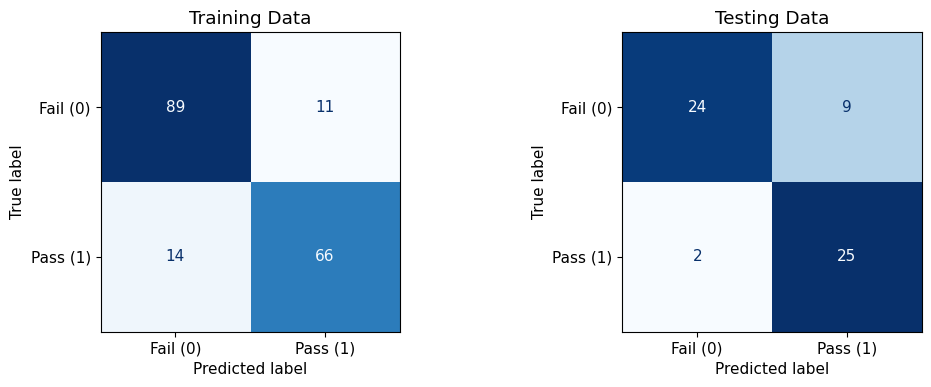

Training Accuracy: 86.11%
Testing Accuracy:  81.67%


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

# Set threshold
threshold = 0.5

# 1. Predictions on training data
train_prob = model.predict_proba(X_train)[:, pass_column]
train_pred = (train_prob >= threshold).astype(int)

# 2. Predictions on testing data
test_prob = model.predict_proba(X_test)[:, pass_column]
test_pred = (test_prob >= threshold).astype(int)

# 3. Create confusion matrices
cm_train = confusion_matrix(y_train, train_pred, labels=[0, 1])
cm_test = confusion_matrix(y_test, test_pred, labels=[0, 1])

# 4. Visualize side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    cm_train, display_labels=["Fail (0)", "Pass (1)"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Training Data")

ConfusionMatrixDisplay(
    cm_test, display_labels=["Fail (0)", "Pass (1)"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)

axes[1].set_title("Testing Data")

plt.tight_layout()
plt.show()

# 5. Print accuracy
print(f"Training Accuracy: {accuracy_score(y_train, train_pred)*100:.2f}%")
print(f"Testing Accuracy:  {accuracy_score(y_test, test_pred)*100:.2f}%")

### Same code as above BUT in **Few** lines

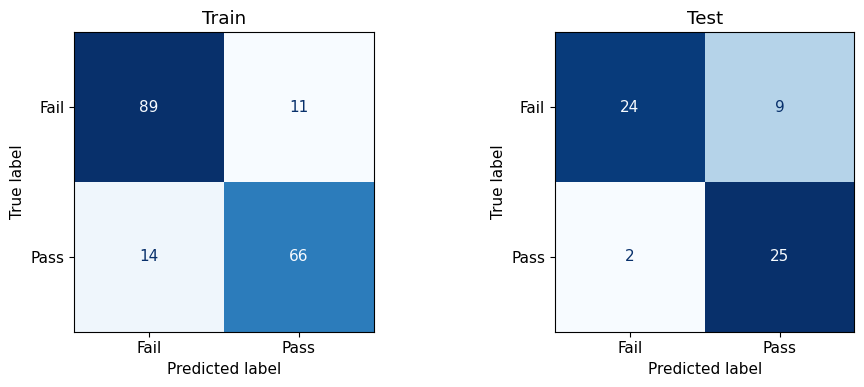

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, X, y, title in zip(
    axes,
    [X_train, X_test],
    [y_train, y_test],
    ["Train", "Test"]
):
    ConfusionMatrixDisplay.from_estimator(
        model, X, y, ax=ax, cmap="Blues",
        display_labels=["Fail", "Pass"], colorbar=False
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

Logistic regression test accuracy: 81.7%
Majority-class baseline accuracy: 55.0%


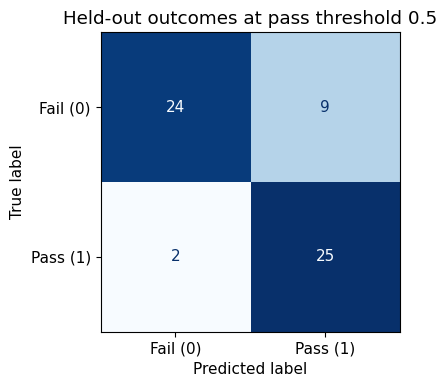

Predicted pass but actually failed (FP): 9
Predicted fail but actually passed (FN): 2
These are simulated held-out results, not evidence of real-world educational performance.


In [ ]:
test_probabilities = model.predict_proba(X_test)[:, pass_column]
fixed_threshold = 0.5
test_predictions = (test_probabilities >= fixed_threshold).astype(int)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
print(f'Logistic regression test accuracy: {accuracy_score(y_test, test_predictions):.1%}')
print(f'Majority-class baseline accuracy: {accuracy_score(y_test, baseline_predictions):.1%}')
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Fail (0)', 'Pass (1)']).plot(cmap='Blues', colorbar=False)
plt.title('Held-out outcomes at pass threshold 0.5')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'Predicted pass but actually failed (FP): {fp}')
print(f'Predicted fail but actually passed (FN): {fn}')
print('These are simulated held-out results, not evidence of real-world educational performance.')

## 9. Predict for a new example
Change `new_hours`, then rerun this cell. Keep values within the simulated 0–10-hour range.

**Before running:** what changes if we raise the decision threshold to 0.7? What stays the same?

In [ ]:
new_hours = 6.0  # Student activity: try 2.0, 5.0, and 8.0.
new_threshold = 0.5  # Then try 0.7.
new_student = pd.DataFrame({'hours_studied': [new_hours]})
new_probability = float(model.predict_proba(new_student)[0, pass_column])
new_decision = int(new_probability >= new_threshold)

print(f'Hours studied: {new_hours:.1f}')
print(f'Estimated probability of passing: {new_probability:.1%}')
print(f'At threshold {new_threshold:.1f}: predict {"PASS" if new_decision else "FAIL"}')
print('This is a model estimate, not a guaranteed outcome or an exam-score prediction.')

Hours studied: 6.0
Estimated probability of passing: 64.9%
At threshold 0.5: predict PASS
This is a model estimate, not a guaranteed outcome or an exam-score prediction.


### Predict on Single example

In [ ]:
# Change these values
hours = 6
threshold = 0.7

# New student
new_student = pd.DataFrame({"hours_studied": [hours]})

# Get probability and prediction
probability = model.predict_proba(new_student)[0, pass_column]
prediction = int(probability >= threshold)

print(f"Hours Studied: {hours}")
print(f"Pass Probability: {probability * 100:.2f}%")
print(f"Threshold: {threshold * 100:.0f}%")
print("Prediction:", "PASS" if prediction == 1 else "FAIL")

Hours Studied: 6
Pass Probability: 64.85%
Threshold: 70%
Prediction: FAIL


### Test on multiple examples at once

In [ ]:
# Change these values
hours = [2, 4, 6, 8, 10]
threshold = 0.7

# New students
new_students = pd.DataFrame({"hours_studied": hours})

# Get probabilities
probabilities = model.predict_proba(new_students)[:, pass_column]

# Add results
new_students["Pass Probability (%)"] = (probabilities * 100).round(2)
new_students["Prediction"] = [
    "PASS" if p >= threshold else "FAIL"
    for p in probabilities
]

display(new_students)

,hours_studied,Pass Probability (%),Prediction
0,2,4.04,FAIL
1,4,21.79,FAIL
2,6,64.85,FAIL
3,8,92.44,PASS
4,10,98.78,PASS


# 10. ROC curve and AUC: compare two models
A confusion matrix uses one threshold. The ROC curve shows the trade-off across thresholds:
- False positive rate (x-axis): fraction of actual fails predicted as pass.
- True positive rate (y-axis, recall): fraction of actual passes predicted as pass.
AUC summarizes the curve: 1.0 means perfect ranking; 0.5 means chance-level ranking. Higher is better for ranking, but AUC is not accuracy or a measure of probability calibration.

Compare logistic regression with a small decision tree (a model that splits inputs using simple rules). Both use the same training and test sets. Use probabilities, not predicted labels: ROC evaluates different thresholds automatically. The positive class is 1 = pass.

Logistic regression AUC: 0.895
Decision tree AUC: 0.874


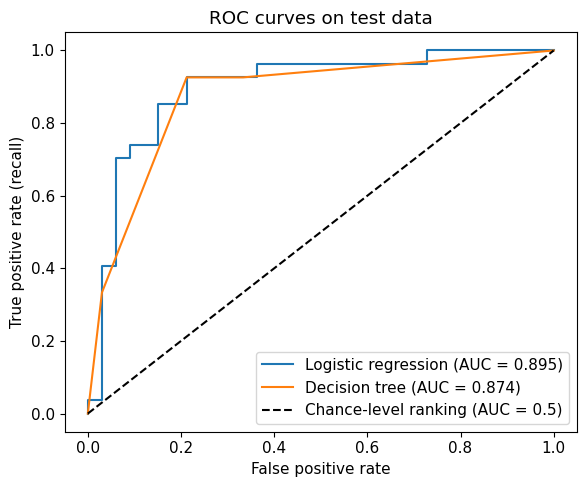

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, roc_auc_score

# Fit a simple comparison model using training data only.
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X_train, y_train)

plt.figure(figsize=(6, 5))
for name, classifier in [("Logistic regression", model), ("Decision tree", tree)]:
    # Column 1 is P(pass), since the labels are 0 and 1.
    probabilities = classifier.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
    print(f"{name} AUC: {auc:.3f}")

plt.plot([0, 1], [0, 1], "k--", label="Chance-level ranking (AUC = 0.5)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on test data")
plt.legend()
plt.tight_layout()
plt.show()